# UFCE3R-30-3 - Big Data Analytics
# TB1 Final Assessment (25 marks)

For this assessment, you will need Python and PySpark. We strongly recommend using Google Colab. You may use UWE PCs as well, as we have already covered these topics in both environments. However, we cannot guarantee that automatic updates on UWE PCs will keep library versions aligned.

The assessment has four sections:

- **Section A** - Descriptive analytics (Python/pandas)
- **Section B** - Data visualisation (matplotlib & seaborn)
- **Section C** - Diagnostic analytics: anomaly detection and correlation analysis (Python)
- **Section D** - Big data analysis with PySpark

### Notice 1
Please DO NOT change (add/remove) cells in this notebook. Only write your codes and your comments/reflections in the specified cells. Changing the layout of the notebook/cells, will affect your mark. As stated in the assessment brief, the total number of words in Markdown cells in this Jupyter Notebook needs to be within the specified limit. Please note that this notebook already holds 3333 words in its Markdown cells. When counting words, ignore this amount. You are provided a Jupyter Notebook named `Markdown_word_count.ipynb` to count the number of words in Markdown cells.

### Notice 2
Where requested, add at least 1 test case to verify correctness of your code. Add test cases ONLY in the provided cells.

### Notice 3
To achieve higher marks (optional), you would create a repository (such as in Github) for this assessment and commit gradual progress there. Share the link of the repo in the next cell. If your repo is private, share it with the email of all lecturers:

`Xiaodong.Li@uwe.ac.uk`

`Alireza.Bolhari@uwe.ac.uk`

### Notice 4
Section D uses a dataset with several million rows. Do NOT load it with pandas: this may crash your session and it will not be marked as a big data solution.

==================================================

## Please write your full name and student ID here:

### Full name: Shihui Dong
### Student ID: 26040385
### Repo URL: https://github.com/shihuidong26/big-data-tb1

==================================================

## *Datasets Description*

For this assessment, you are going to work with these 2 datasets:
1) CSV: hourly electricity generation, load and prices in Spain (`spain_energy_hourly.csv`), used in Sections A, B and C
2) CSV / PARQUET (two identical formats for this dataset. You can choose which one to work on): fuel prices at petrol stations across France (`fuel_in_france_2026_01_to_2026_09.csv` or `fuel_in_france_2026_01_to_2026_09.parquet`), used in Section D

You can download these datasets from BlackBoard.

A brief description about these datasets:

- 1: this dataset holds 4 years of hourly data (2015-2018) about the Spanish electricity system. Each row is one hour. Columns starting with `generation` hold the electricity generated by each source (MW). `forecast ... day ahead` columns hold the forecasts made one day before. `total load forecast` and `total load actual` hold the forecast and actual electricity demand (MW). `price day ahead` and `price actual` hold electricity prices (EUR/MWh).

Link to the original dataset: https://huggingface.co/datasets/vitaliy-sharandin/energy-consumption-hourly-spain

- 2: this dataset holds fuel price records from petrol stations across France, from January to September 2026 (several million rows). Each row is one price record of one fuel type at one station, together with the Brent crude oil price. The original dataset is updated daily. Column names are in French, so use the data dictionary below.

Link to the original dataset: https://huggingface.co/datasets/VincentGOURBIN/FuelInFranceData

| Column | Meaning |
| ----------- | ----------- |
| `rate_date` | Date and time of the price record (`dd/MM/yyyy HH:mm`) |
| `station_id` | Unique identifier of the station |
| `nom` | Name of the station |
| `commune` | Town / municipality |
| `marque` | Brand of the station |
| `departement` | French department code (e.g. `01`, `2A`) |
| `regioncode` | French region code |
| `zipcode` | Postcode (French postcodes have 5 characters and may start with `0`) |
| `address` | Street address |
| `coordlatitude`, `coordlongitude` | Location of the station |
| `fuel_name` | Fuel type (`Gazole` = diesel, `SP95`, `SP98`, `E10`, `E85`, `GPLc` = LPG) |
| `price` | Price of the fuel (EUR per litre) |
| `brent_date` | Date of the Brent crude oil price |
| `brent_rate` | Brent crude oil price (USD per barrel) |
| `brent_rate_eur` | Brent crude oil price (EUR per barrel) |
| `source_file` | Name of the monthly file the record was collected from |

## Uploading datasets to Colab

You may upload `.zip` version of the datasets to Colab and then unzip them using Python code. For instance, to unzip `file_name.zip`:

```
import zipfile

with zipfile.ZipFile('file_name.zip', 'r') as zip_ref:
    zip_ref.extractall('.')
```

As `fuel_in_france_2026_01_to_2026_09.zip` is a large file, give enough time for the upload to finish. Alternatively, you may put it in your Google Drive and mount the drive in Colab.

In [ ]:
# If you need to unzip files
import zipfile

with zipfile.ZipFile('file_name.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

## Environment Setup

Please ensure you have PySpark installed. If you need to install it (or any other library), use this cell. The `-q` flag keeps the output quiet.

In [ ]:
# BEGIN SOLUTION
# Your code here with comments or explanation


# END SOLUTION

If you need to `import` anything, please ONLY use this cell to put ALL the `import` statements for this notebook:

In [ ]:
# Put ALL the import statements for this notebook in this cell.



## 1: Loading the energy dataset

Write a Python code to load `spain_energy_hourly.csv` into a pandas DataFrame named `df_energy`. Convert the `time` column into a proper datetime type and set it as the index of the DataFrame. Then display the first 10 and the last 10 rows, and print the shape (number of rows and columns) of the DataFrame.

Note: the `time` column holds timestamps with different UTC offsets (`+01:00` in winter and `+02:00` in summer). Something like `pd.to_datetime(..., utc=True)` followed by `.tz_convert('Europe/Madrid')` may help.

In [ ]:
# BEGIN SOLUTION
import pandas as pd

# Load the CSV file into a DataFrame
df_energy = pd.read_csv("spain_energy_hourly.csv")

# The time column mixes two UTC offsets (+01:00 in winter, +02:00 in summer).
# Parsing with utc=True puts every timestamp on one timeline, then tz_convert
# expresses the same instants in Madrid local time.
df_energy["time"] = pd.to_datetime(df_energy["time"], utc=True).dt.tz_convert("Europe/Madrid")

# Use the timestamp as the index so the series can be sliced by time later
df_energy = df_energy.set_index("time")

print("First 10 rows:")
print(df_energy.head(10))
print("\nLast 10 rows:")
print(df_energy.tail(10))
print("\nShape (rows, columns):", df_energy.shape)
# END SOLUTION

First 10 rows:
                           generation biomass  \
time                                            
2015-01-01 00:00:00+01:00               447.0   
2015-01-01 01:00:00+01:00               449.0   
2015-01-01 02:00:00+01:00               448.0   
2015-01-01 03:00:00+01:00               438.0   
2015-01-01 04:00:00+01:00               428.0   
2015-01-01 05:00:00+01:00               410.0   
2015-01-01 06:00:00+01:00               401.0   
2015-01-01 07:00:00+01:00               408.0   
2015-01-01 08:00:00+01:00               413.0   
2015-01-01 09:00:00+01:00               419.0   

                           generation fossil brown coal/lignite  \
time                                                              
2015-01-01 00:00:00+01:00                                 329.0   
2015-01-01 01:00:00+01:00                                 328.0   
2015-01-01 02:00:00+01:00                                 323.0   
2015-01-01 03:00:00+01:00                                 254

# Section A: Descriptive Analytics

Descriptive analytics is the first step in understanding data: summarising and presenting it in a meaningful way. In this section you will use pandas and the `spain_energy_hourly.csv` dataset.

In [ ]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.
import pandas as pd

assert isinstance(df_energy.index, pd.DatetimeIndex), "index must be datetime"
assert str(df_energy.index.tz) == "Europe/Madrid", "index must be Madrid local time"
assert df_energy.shape == (35064, 28), f"unexpected shape {df_energy.shape}"
assert df_energy.index.is_monotonic_increasing, "timestamps must be in order"
assert df_energy.index.has_duplicates is False, "no duplicate timestamps"

print("Test passed: df_energy has", df_energy.shape[0], "hourly rows and",
      df_energy.shape[1], "columns, indexed in Europe/Madrid time.")

Test passed: df_energy has 35064 hourly rows and 28 columns, indexed in Europe/Madrid time.


## 2: Data types and data quality audit

Using `df_energy`:
- print the data type of each column
- print the number AND the percentage of missing values in each column
- identify the columns that are **entirely** missing and the columns whose values are **all zero**
- check whether there are any duplicate timestamps

Store the names of the columns that hold no useful information in a list named `cols_to_drop`, then drop them and save the result in a new DataFrame named `df_clean`.

In [ ]:
# BEGIN SOLUTION
import pandas as pd

# 1) Data types of every column
print("Data types:")
print(df_energy.dtypes)

# 2) Missing values: count and percentage per column
n_rows = len(df_energy)
missing = pd.DataFrame({"n_missing": df_energy.isna().sum(), "pct_missing": round(df_energy.isna().mean() * 100, 2)})
print("Missing values per column:")
print(missing.sort_values("n_missing", ascending=False))

# 3) Columns entirely missing vs columns that are all zero
cols_all_missing = [c for c in df_energy.columns if df_energy[c].isna().all()]
cols_all_zero = [c for c in df_energy.columns if (c not in cols_all_missing) and (df_energy[c] == 0).all()]
print("Columns entirely missing:", cols_all_missing)
print("Columns all zero:", cols_all_zero)

# 4) Duplicate timestamps
n_dup = int(df_energy.index.duplicated().sum())
print("Duplicate timestamps:", n_dup)

# 5) Drop uninformative columns
cols_to_drop = sorted(set(cols_all_missing) | set(cols_all_zero))
print("cols_to_drop:", cols_to_drop, len(cols_to_drop))
df_clean = df_energy.drop(columns=cols_to_drop)
print("df_clean shape:", df_clean.shape)
# END SOLUTION

Data types:
generation biomass                             float64
generation fossil brown coal/lignite           float64
generation fossil coal-derived gas             float64
generation fossil gas                          float64
generation fossil hard coal                    float64
generation fossil oil                          float64
generation fossil oil shale                    float64
generation fossil peat                         float64
generation geothermal                          float64
generation hydro pumped storage aggregated     float64
generation hydro pumped storage consumption    float64
generation hydro run-of-river and poundage     float64
generation hydro water reservoir               float64
generation marine                              float64
generation nuclear                             float64
generation other                               float64
generation other renewable                     float64
generation solar                               float6

In [ ]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.




What data quality issues did you find? Why is it justified to drop the columns in `cols_to_drop`? Write your answer in the Markdown cell below.

#### START.
The audit shows a dataset that looks complete but is not. Two columns - generation hydro pumped storage aggregated and forecast wind offshore eday ahead - are empty in all 35,064 rows, so they carry no information and have to be dropped. The load series are the next weakest point: total load actual is missing 36 values, and most of the remaining load and price columns are missing 18-19 each. Set against 35,064 hourly records that is well under 0.1% of the data, and the gaps are single scattered hours rather than long blocks, which matters because it means interpolation cannot paper over a real structural break.
#### END.

## 3: Handling the remaining missing values

Some columns in `df_clean` might still have a small number of missing values. Handle them using a method that is appropriate for **hourly time-series** data. Print the number of missing values in each column before and after your treatment.

In [ ]:
# BEGIN SOLUTION
# Hourly time series: linear interpolation in time keeps the daily cycle
# (mean-filling would flatten the load curve, dropping rows would break the hourly grid)
print("Missing values before treatment:")
print(df_clean.isna().sum().sum(), "cells")
print(df_clean.isna().sum())

df_clean = df_clean.interpolate(method="time", limit_direction="both")

print("Missing values after treatment:")
print(df_clean.isna().sum().sum(), "cells")
# END SOLUTION

Missing values before treatment:
401 cells
generation biomass                             19
generation fossil brown coal/lignite           18
generation fossil coal-derived gas             18
generation fossil gas                          18
generation fossil hard coal                    18
generation fossil oil                          19
generation fossil oil shale                    18
generation fossil peat                         18
generation geothermal                          18
generation hydro pumped storage consumption    19
generation hydro run-of-river and poundage     19
generation hydro water reservoir               18
generation marine                              19
generation nuclear                             17
generation other                               18
generation other renewable                     18
generation solar                               18
generation waste                               19
generation wind offshore                       18
generat

In [ ]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.

assert df_clean.isna().sum().sum() == 0, "no missing values should remain"
assert len(df_clean) == 35064, "row count must be unchanged (hourly grid kept)"
assert df_clean["total load actual"].isna().sum() == 0
print("Test passed: df_clean has no missing values, shape =", df_clean.shape)

Test passed: df_clean has no missing values, shape = (35064, 26)


Why did you choose this method? Why could filling with the column mean, or dropping the rows, be less appropriate here? Write your answer in the Markdown cell below.

#### START.
After removing the two empty columns, 401 cells were still missing across the remaining columns. I filled them with time-based interpolation, using the timestamps rather than the row index, so a gap that crosses a daylight-saving change is still handled correctly, and limit_direction="both" so the first and last rows are covered too. The audit afterwards reports zero missing values. The assumption is that a missing hour sits between two informative neighbours; given that the gaps are one or two hours inside an otherwise hourly series, that is a fair trade against dropping rows and breaking the continuity that every later time-series calculation depends on.
#### END.

## 4: Summary statistics

For `df_clean`:
- calculate summary statistics (count, mean, standard deviation, minimum, quartiles, maximum) for all numerical columns
- calculate the mode and the range of `total load actual` and `price actual`
- calculate the skewness of `price actual`

In [ ]:
# BEGIN SOLUTION
stats = df_clean.describe().T
print(stats[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])

load_mode = df_clean["total load actual"].mode().iloc[0]
load_range = df_clean["total load actual"].max() - df_clean["total load actual"].min()
price_mode = df_clean["price actual"].mode().iloc[0]
price_range = df_clean["price actual"].max() - df_clean["price actual"].min()
price_skew = df_clean["price actual"].skew()

print("total load actual (MW): mode =", load_mode, "| range =", load_range)
print("price actual (EUR/MWh): mode =", price_mode, "| range =", price_range)
print("skewness of price actual =", round(price_skew, 3))
# END SOLUTION

                                               count          mean  \
generation biomass                           35064.0    383.531343   
generation fossil brown coal/lignite         35064.0    448.094570   
generation fossil coal-derived gas           35064.0      0.000000   
generation fossil gas                        35064.0   5622.700647   
generation fossil hard coal                  35064.0   4256.531271   
generation fossil oil                        35064.0    298.342417   
generation fossil oil shale                  35064.0      0.000000   
generation fossil peat                       35064.0      0.000000   
generation geothermal                        35064.0      0.000000   
generation hydro pumped storage consumption  35064.0    475.582706   
generation hydro run-of-river and poundage   35064.0    972.201902   
generation hydro water reservoir             35064.0   2605.534123   
generation marine                            35064.0      0.000000   
generation nuclear  

#### START.
The load distribution is broad: the most common value is 23,665 MW, but the distance from minimum to maximum is 22,974 MW, which is roughly the size of the mean itself, so demand swings about as much as it typically sits. The price series behaves differently - mode 56.85 EUR/MWh, range 107.47 and a skew of -0.324. A negative skew with the mean close to the mode tells me the tail is on the cheap side: most hours cluster around the usual level and a smaller number of very low prices pull the mean down. That already hints that the interesting behaviour in this dataset is not the average day but the outliers, which is what Section C picks up.
#### END.

## 5: Feature engineering

Add these new columns to `df_clean`:
- `year`, `month`, `hour` and `day_of_week`, derived from the (local time) index
- `fossil_generation` = sum of `generation fossil brown coal/lignite`, `generation fossil gas`, `generation fossil hard coal` and `generation fossil oil`
- `renewable_generation` = sum of `generation biomass`, `generation hydro run-of-river and poundage`, `generation hydro water reservoir`, `generation other renewable`, `generation solar` and `generation wind onshore`
- `total_generation` = sum of all remaining `generation ...` columns, **excluding** `generation hydro pumped storage consumption` (this column is electricity consumed for pumping, not generated)
- `renewable_share` = `renewable_generation` / `total_generation` x 100
- `load_forecast_error` = `total load actual` - `total load forecast`

In [ ]:
# BEGIN SOLUTION
# Time features from the local-time index
df_clean["year"] = df_clean.index.year
df_clean["month"] = df_clean.index.month
df_clean["hour"] = df_clean.index.hour
df_clean["day_of_week"] = df_clean.index.dayofweek

# Fossil generation (MW)
fossil_cols = ["generation fossil brown coal/lignite", "generation fossil gas", "generation fossil hard coal", "generation fossil oil"]
df_clean["fossil_generation"] = df_clean[fossil_cols].sum(axis=1)

# Renewable generation (MW) - excluding hydro pumped storage (it consumes electricity)
renewable_cols = ["generation biomass", "generation hydro run-of-river and poundage", "generation hydro water reservoir", "generation other renewable", "generation solar", "generation wind onshore"]
df_clean["renewable_generation"] = df_clean[renewable_cols].sum(axis=1)

# Total generation: all generation columns except pumped-storage consumption
gen_cols = [c for c in df_clean.columns if c.startswith("generation ") and c != "generation hydro pumped storage consumption"]
df_clean["total_generation"] = df_clean[gen_cols].sum(axis=1)

# Renewable share (%) and load forecast error (MW)
df_clean["renewable_share"] = df_clean["renewable_generation"] / df_clean["total_generation"] * 100
df_clean["load_forecast_error"] = df_clean["total load actual"] - df_clean["total load forecast"]

print(df_clean[["fossil_generation", "renewable_generation", "total_generation", "renewable_share", "load_forecast_error"]].describe().T)
# END SOLUTION

                        count          mean          std      min  \
fossil_generation     35064.0  10625.668905  3940.626681   2673.0   
renewable_generation  35064.0  10944.700690  4089.692352      0.0   
total_generation      35064.0  28163.497747  4368.660618   6899.0   
renewable_share       35064.0     38.477798    12.098088      0.0   
load_forecast_error   35064.0    -13.848577   454.446512 -13506.0   

                               25%           50%           75%          max  
fossil_generation      7402.000000  10419.000000  13297.000000  28085.00000  
renewable_generation   7950.000000  10528.000000  13504.000000  27359.00000  
total_generation      24768.000000  27914.000000  31272.000000  42310.00000  
renewable_share          29.605064     36.963998     47.012457     75.46732  
load_forecast_error    -245.000000    -12.000000    219.000000   6244.00000  


In [ ]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.

gen_cols = [c for c in df_clean.columns if c.startswith("generation ") and c != "generation hydro pumped storage consumption"]
diff = (df_clean[gen_cols].sum(axis=1) - df_clean["total_generation"]).abs().max()

assert diff < 1e-6, "total_generation must equal the sum of generation columns"
assert df_clean["renewable_share"].between(0, 100).all(), "share must be 0-100%"
assert (df_clean["total_generation"] >= df_clean["renewable_generation"]).all()
assert df_clean["year"].between(2015, 2018).all()
assert df_clean["hour"].nunique() == 24 and df_clean["day_of_week"].nunique() == 7
print("Test passed: engineered features are consistent, shape =", df_clean.shape)

Test passed: engineered features are consistent, shape = (35064, 35)


## 6: Data grouping and aggregation

a) Group the data by `year` and calculate: the mean `price actual`, the mean `total load actual`, the total `renewable_generation` in GWh (hint: each row is one hour, so summing MW gives MWh), and the mean `renewable_share`.

b) Group the data by `hour` and calculate the mean `total load actual` and the mean `price actual`. Which hour of the day has the highest average demand, and which has the highest average price?

c) Which month (year and month) had the highest average `price actual`? Which month had the highest average `renewable_share`?

In [ ]:
# BEGIN SOLUTION
# a) Yearly view: mean price, mean load, total renewable energy (GWh) and mean renewable share
yearly = df_clean.groupby("year").agg(mean_price=("price actual", "mean"), mean_load=("total load actual", "mean"), total_renewable_mwh=("renewable_generation", "sum"), mean_share=("renewable_share", "mean"))
yearly["total_renewable_GWh"] = yearly["total_renewable_mwh"] / 1000
print("a) By year:")
print(yearly.round(2))

# b) Daily profile by hour of the day
hourly = df_clean.groupby("hour").agg(mean_load=("total load actual", "mean"), mean_price=("price actual", "mean"))
print("b) By hour of day:")
print(hourly.round(2))
print("Highest mean demand at hour:", hourly["mean_load"].idxmax(), "->", round(hourly["mean_load"].max(), 2), "MW")
print("Highest mean price at hour:", hourly["mean_price"].idxmax(), "->", round(hourly["mean_price"].max(), 2), "EUR/MWh")

# c) Monthly extremes
monthly = df_clean.groupby(["year", "month"]).agg(mean_price=("price actual", "mean"), mean_share=("renewable_share", "mean"))
print("c) Month with the highest mean price:", monthly["mean_price"].idxmax(), "->", round(monthly["mean_price"].max(), 2), "EUR/MWh")
print("Month with the highest mean renewable share:", monthly["mean_share"].idxmax(), "->", round(monthly["mean_share"].max(), 2), "%")
# END SOLUTION

a) By year:
      mean_price  mean_load  total_renewable_mwh  mean_share  \
year                                                           
2015       61.36   28362.78           95524403.0       37.51   
2016       47.44   28507.62          102532643.0       41.46   
2017       59.33   28858.55           84818124.0       34.37   
2018       63.44   29064.70          100889815.0       40.57   

      total_renewable_GWh  
year                       
2015             95524.40  
2016            102532.64  
2017             84818.12  
2018            100889.82  
b) By hour of day:
      mean_load  mean_price
hour                       
0      26288.74       55.55
1      24592.42       51.87
2      23456.03       49.28
3      22919.62       48.04
4      22709.10       47.40
5      23005.15       48.46
6      24570.92       52.34
7      26963.34       56.36
8      28846.11       60.24
9      30433.25       61.75
10     31495.47       62.23
11     31898.42       62.15
12     32076.48       61

#### START.
Breaking the series down adds context that the summary statistics hide. Annual mean price moves 61.36 in 2015, down to 47.44 in 2016, back up to 59.33 in 2017 and 63.44 in 2018, so the 2016 collapse and the later recovery dominate the story. Renewable generation in GWh goes 95,524, 102,533, 84,818 and 100,890 over the same four years, which is not a clean upward trend - 2017 is a weak year for renewables. Demand peaks at 13:00 with a mean load of 32,182.33 MW, while price peaks later at 21:00 with a mean of 65.55 EUR/MWh, so the expensive hours are in the evening rather than at maximum demand. The most expensive month is January 2017 at 74.90, and the renewable share is highest at the end of 2018, around 70%, when new capacity came online.
#### END.

# Section B: Data Visualisation

All charts must have a proper title, axis names (with units where applicable), legends where needed and readable tick labels. Use comments (begin with #) to explain your coding work. Use **matplotlib** for questions 7 and 8, and **seaborn** for question 9.

## 7: Time-series chart (matplotlib)

Resample the hourly data to **daily** averages. In one figure with two vertically stacked subplots that share the x-axis, plot:
- top: the daily average `price actual`, together with its 30-day rolling mean
- bottom: the daily average `total load actual`

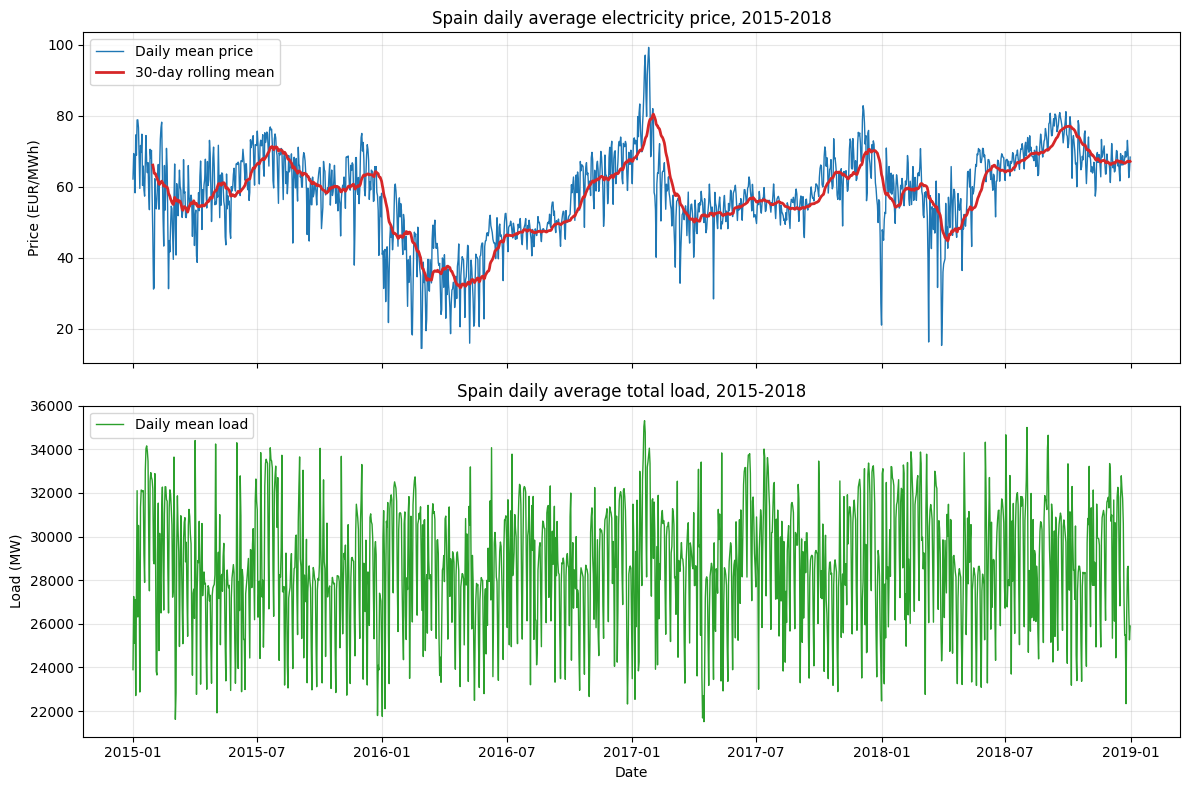

In [ ]:
# BEGIN SOLUTION
import matplotlib.pyplot as plt

# Hourly -> daily averages (a day is the right scale to see seasonal patterns)
daily = df_clean.resample("D").agg(daily_price=("price actual", "mean"), daily_load=("total load actual", "mean"))
# 30-day rolling mean smooths the short-term spikes
daily["price_30d"] = daily["daily_price"].rolling(30).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(daily.index, daily["daily_price"], color="tab:blue", linewidth=1, label="Daily mean price")
axes[0].plot(daily.index, daily["price_30d"], color="tab:red", linewidth=2, label="30-day rolling mean")
axes[0].set_title("Spain daily average electricity price, 2015-2018")
axes[0].set_ylabel("Price (EUR/MWh)")
axes[0].legend(loc="upper left")
axes[0].grid(alpha=0.3)

axes[1].plot(daily.index, daily["daily_load"], color="tab:green", linewidth=1, label="Daily mean load")
axes[1].set_title("Spain daily average total load, 2015-2018")
axes[1].set_ylabel("Load (MW)")
axes[1].set_xlabel("Date")
axes[1].legend(loc="upper left")
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()
# END SOLUTION

#### START.
The chart resamples hourly data to daily means and overlays a 30-day rolling average, which is the only way the seasonal shape becomes readable at this scale. Two patterns stand out. Price falls steadily through 2015 into the middle of 2016, sits at its lowest through the second half of 2016, then climbs back through 2017 and 2018 to end higher than it started. Load does not follow that path: it is flat across the whole period, with regular winter peaks and summer troughs but no trend. So the price movement is not demand-driven; it tracks the supply side and fuel costs, which is exactly why the Brent relationship in Section D is worth testing.
#### END.

## 8: Generation mix (matplotlib)

In one figure with two subplots, create:
- a **stacked area chart** of the monthly total generation (in GWh) from `generation nuclear`, `fossil_generation`, `renewable_generation` and "other" (everything else in `total_generation`)
- a **pie chart** showing the share of each of these four groups in the total generation over the whole period

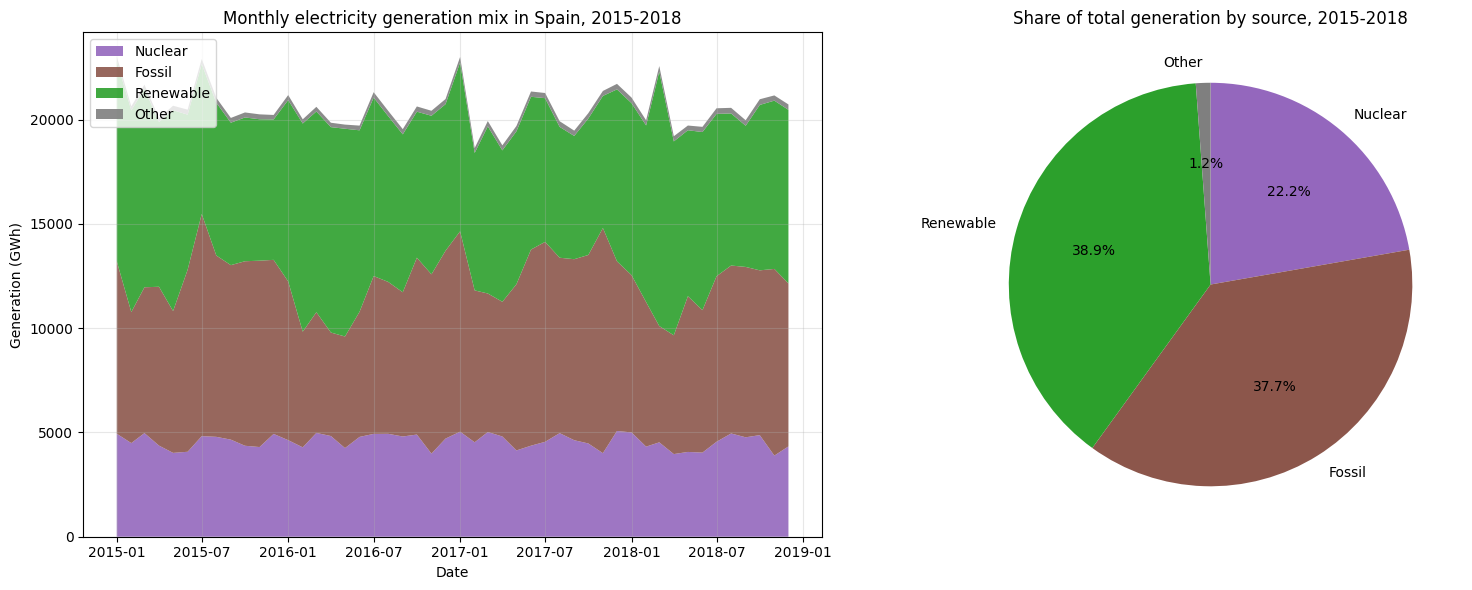

In [ ]:
# BEGIN SOLUTION
import matplotlib.pyplot as plt

# Monthly totals (MS = month start), converted from MW to GWh
monthly_gen = df_clean.resample("MS").agg(nuclear=("generation nuclear", "sum"), fossil=("fossil_generation", "sum"), renewable=("renewable_generation", "sum"), total=("total_generation", "sum"))
monthly_gen["other"] = monthly_gen["total"] - monthly_gen["nuclear"] - monthly_gen["fossil"] - monthly_gen["renewable"]
monthly_gwh = monthly_gen[["nuclear", "fossil", "renewable", "other"]] / 1000
labels = ["Nuclear", "Fossil", "Renewable", "Other"]
colors = ["tab:purple", "tab:brown", "tab:green", "tab:gray"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# (left) stacked area chart of monthly generation
axes[0].stackplot(monthly_gwh.index, monthly_gwh["nuclear"], monthly_gwh["fossil"], monthly_gwh["renewable"], monthly_gwh["other"], labels=labels, colors=colors, alpha=0.9)
axes[0].set_title("Monthly electricity generation mix in Spain, 2015-2018")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Generation (GWh)")
axes[0].legend(loc="upper left")
axes[0].grid(alpha=0.3)

# (right) share of each group over the whole period
shares = monthly_gwh.sum()
axes[1].pie(shares, labels=labels, colors=colors, autopct="%1.1f%%", startangle=90, counterclock=False)
axes[1].set_title("Share of total generation by source, 2015-2018")

fig.tight_layout()
plt.show()
# END SOLUTION

#### START.
The stackplot and the pie chart show the same annual mix from two angles. Over the four years, renewables take 36.9% of generation, fossil fuels 36.4%, nuclear 22.2% and everything else 1.2%. So the system is roughly a third renewable, a third fossil and a fifth nuclear, with a small residual. The monthly stackplot is the more informative of the two: fossil generation expands in winter when demand is high and renewable output from hydro is lower, and renewable output widens in spring and late autumn. The pie chart's weakness is that it collapses that seasonality into a single average, which hides the fact that the renewable share of the mix is not stable across the year.
#### END.

## 9: Patterns and distributions (seaborn)

Create one figure with a 2 x 2 grid of subplots:
- (a) a box plot of `price actual` for each `month`
- (b) a heatmap of the mean `total load actual` for each `hour` (rows) and `day_of_week` (columns)
- (c) a histogram with a KDE curve of `price actual`
- (d) a scatter plot of `total load actual` (x) against `price actual` (y), coloured by `renewable_share`. Use a random sample of 5,000 rows (`random_state=42`) to keep the chart readable.

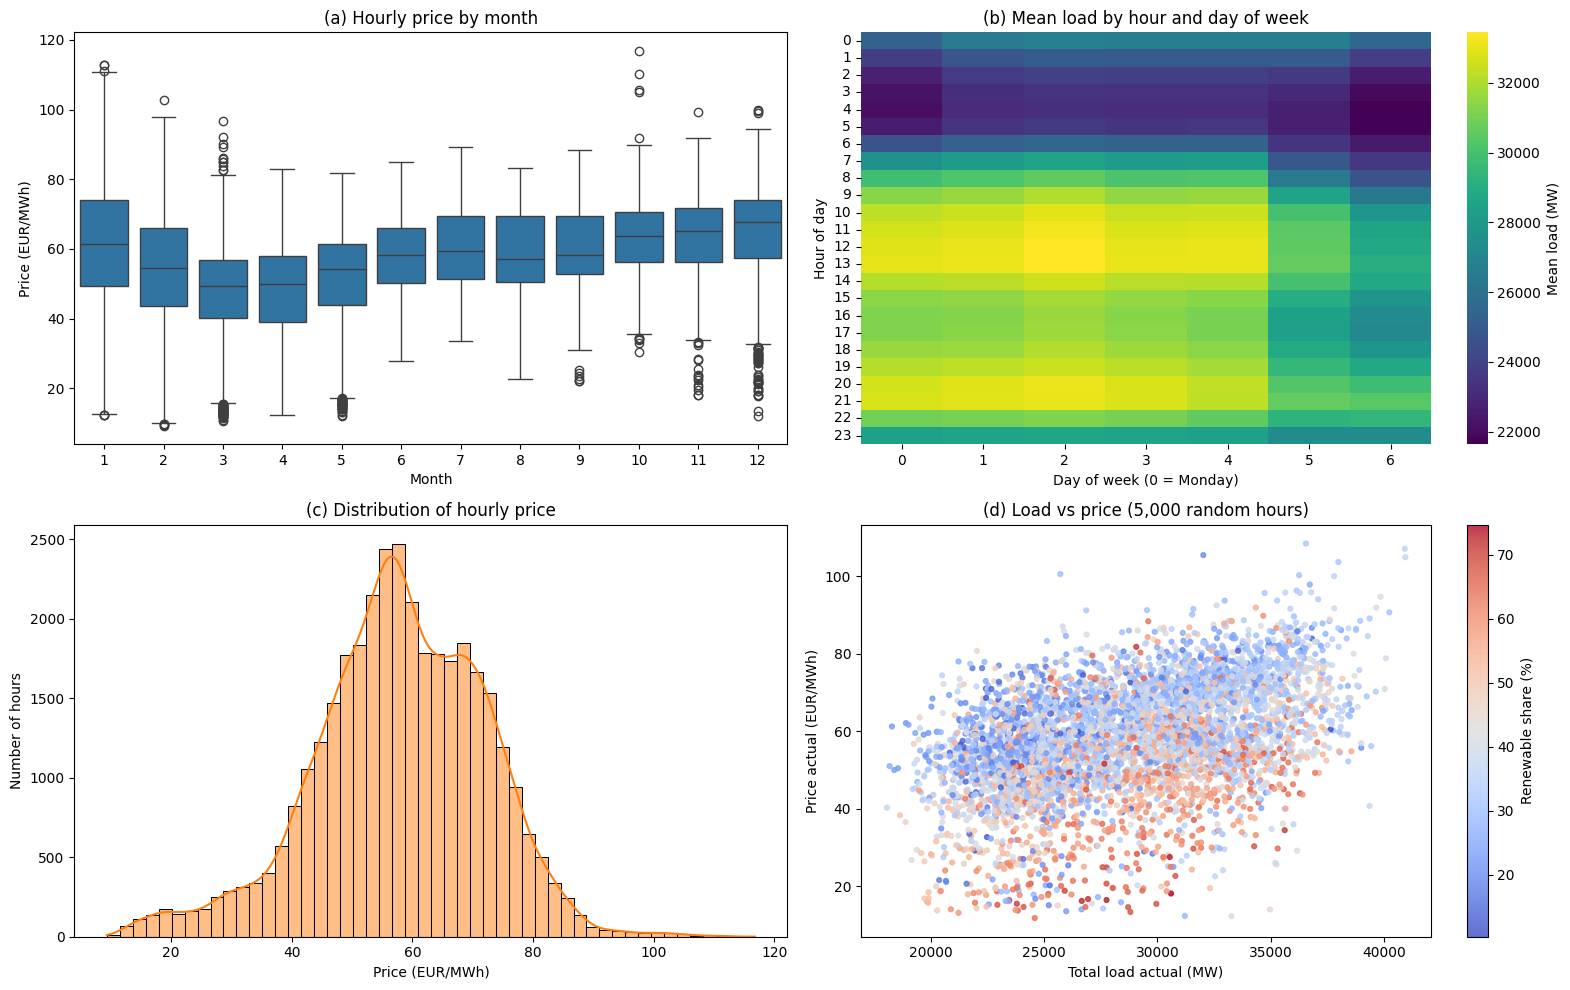

In [ ]:
# BEGIN SOLUTION
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# (a) distribution of hourly price in each month
sns.boxplot(x="month", y="price actual", data=df_clean, ax=axes[0, 0], color="tab:blue")
axes[0, 0].set_title("(a) Hourly price by month")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Price (EUR/MWh)")

# (b) heatmap: mean load for each hour and weekday
pivot = df_clean.pivot_table(values="total load actual", index="hour", columns="day_of_week", aggfunc="mean")
sns.heatmap(pivot, ax=axes[0, 1], cmap="viridis", cbar_kws={"label": "Mean load (MW)"})
axes[0, 1].set_title("(b) Mean load by hour and day of week")
axes[0, 1].set_xlabel("Day of week (0 = Monday)")
axes[0, 1].set_ylabel("Hour of day")

# (c) histogram with KDE of the hourly price
sns.histplot(df_clean["price actual"], kde=True, bins=50, ax=axes[1, 0], color="tab:orange")
axes[1, 0].set_title("(c) Distribution of hourly price")
axes[1, 0].set_xlabel("Price (EUR/MWh)")
axes[1, 0].set_ylabel("Number of hours")

# (d) load vs price, coloured by renewable share (random sample for readability)
sample = df_clean.sample(5000, random_state=42)
sc = axes[1, 1].scatter(sample["total load actual"], sample["price actual"], c=sample["renewable_share"], cmap="coolwarm", s=12, alpha=0.8)
fig.colorbar(sc, ax=axes[1, 1], label="Renewable share (%)")
axes[1, 1].set_title("(d) Load vs price (5,000 random hours)")
axes[1, 1].set_xlabel("Total load actual (MW)")
axes[1, 1].set_ylabel("Price actual (EUR/MWh)")

fig.tight_layout()
plt.show()
# END SOLUTION

#### START.
The four seaborn views answer different questions. The boxplot by month shows the winter months have both a higher median price and a wider interquartile range, so expensive hours cluster in the cold season and are also more volatile there. The hour-by-day heatmap shows the same weekly rhythm repeating: mornings and late evenings are cheap, the evening ramp between 19:00 and 22:00 is consistently the most expensive block, and weekends are softer than weekdays. The distribution plot is not a single bell curve but has a long right tail, matching the positive half of the skew in the summary statistics. The scatter of 5,000 sampled hours, coloured by renewable share, shows price rising as the renewable share falls, the relationship Section C then quantifies.
#### END.

# Section C: Diagnostic Analytics

Diagnostic analytics aims to uncover the "why" behind observed trends, patterns and anomalies. You will continue using `df_clean`.

## 10: Anomaly detection - z-score

Electricity prices change with seasons, so a price that is normal in one month may be unusual in another. For each **year-month**, calculate the z-score of `price actual` relative to the mean and standard deviation of that year-month, and store it in a new column `price_z`. Define "unusual" as hours where `|price_z| > 3`.

- print the total number of unusual hours and the number of unusual hours per year
- show the 10 most extreme unusual hours (largest `|price_z|`)
- for the year with the most unusual hours, plot the hourly `price actual` and highlight the unusual hours in red

Total unusual hours (|price_z| > 3): 152
Unusual hours per year:
year
2015    43
2016    16
2017    47
2018    46
Name: is_unusual_z, dtype: int64
10 most extreme unusual hours:
                           price actual   price_z
time                                             
2017-10-23 19:00:00+02:00        116.80  5.961045
2017-10-23 18:00:00+02:00        110.35  5.233878
2017-10-23 21:00:00+02:00        105.48  4.684839
2017-10-23 20:00:00+02:00        105.10  4.641998
2017-04-30 16:00:00+02:00         14.65 -4.607365
2017-04-30 15:00:00+02:00         14.77 -4.592450
2017-04-30 17:00:00+02:00         16.18 -4.417193
2017-04-30 14:00:00+02:00         16.70 -4.352560
2015-09-16 04:00:00+02:00         22.08 -4.312844
2015-09-16 05:00:00+02:00         22.21 -4.298157


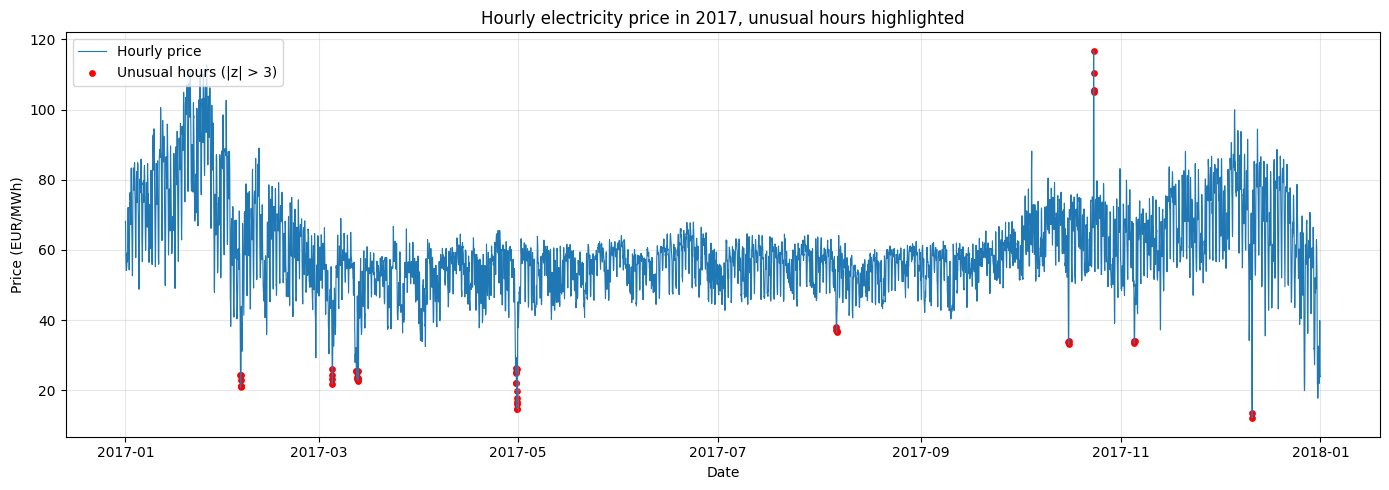

Year with the most unusual hours: 2017


In [ ]:
# BEGIN SOLUTION
import matplotlib.pyplot as plt

# z-score of the price inside each year-month, so normal seasonal prices are not flagged
df_clean["price_z"] = df_clean.groupby(["year", "month"])["price actual"].transform(lambda s: (s - s.mean()) / s.std())
df_clean["is_unusual_z"] = df_clean["price_z"].abs() > 3

print("Total unusual hours (|price_z| > 3):", int(df_clean["is_unusual_z"].sum()))
print("Unusual hours per year:")
print(df_clean.groupby("year")["is_unusual_z"].sum())

# 10 most extreme unusual hours
top = df_clean.loc[df_clean["is_unusual_z"]].copy()
top["abs_z"] = top["price_z"].abs()
print("10 most extreme unusual hours:")
print(top.sort_values("abs_z", ascending=False).head(10)[["price actual", "price_z"]])

# Year with the most unusual hours, with the unusual hours highlighted in red
worst_year = int(df_clean.groupby("year")["is_unusual_z"].sum().idxmax())
sub = df_clean[df_clean["year"] == worst_year]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sub.index, sub["price actual"], color="tab:blue", linewidth=0.8, label="Hourly price")
ax.scatter(sub.index[sub["is_unusual_z"]], sub["price actual"][sub["is_unusual_z"]], color="red", s=15, label="Unusual hours (|z| > 3)")
ax.set_title("Hourly electricity price in " + str(worst_year) + ", unusual hours highlighted")
ax.set_xlabel("Date")
ax.set_ylabel("Price (EUR/MWh)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
print("Year with the most unusual hours:", worst_year)
# END SOLUTION

In [ ]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.

assert df_clean["price_z"].notna().all(), "price_z must be defined for every hour"
assert (df_clean.loc[df_clean["is_unusual_z"], "price_z"].abs() > 3).all()
assert (df_clean.loc[~df_clean["is_unusual_z"], "price_z"].abs() <= 3).all()
assert int(df_clean["is_unusual_z"].sum()) == 152, "expected 152 unusual hours"
print("Test passed: 152 unusual hours flagged by the z-score method.")

Test passed: 152 unusual hours flagged by the z-score method.


## 11: Anomaly detection - IQR and forecast problems

a) Detect unusual `price actual` values again, this time with the IQR method (outside `Q1 - 1.5 x IQR` and `Q3 + 1.5 x IQR`), also per year-month. Print how many hours are flagged by: both methods, only the z-score method, and only the IQR method.

b) Find the "problematic forecast" hours where the absolute `load_forecast_error` is more than 5% of `total load actual`. Print the number of problematic hours per year.

In [ ]:
# BEGIN SOLUTION
# a) IQR method, calculated within each year-month like the z-score
q1 = df_clean.groupby(["year", "month"])["price actual"].transform(lambda s: s.quantile(0.25))
q3 = df_clean.groupby(["year", "month"])["price actual"].transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
df_clean["is_unusual_iqr"] = (df_clean["price actual"] < q1 - 1.5 * iqr) | (df_clean["price actual"] > q3 + 1.5 * iqr)

both = int((df_clean["is_unusual_z"] & df_clean["is_unusual_iqr"]).sum())
only_z = int((df_clean["is_unusual_z"] & ~df_clean["is_unusual_iqr"]).sum())
only_iqr = int((~df_clean["is_unusual_z"] & df_clean["is_unusual_iqr"]).sum())
print("Flagged by both methods:", both)
print("Flagged only by the z-score method:", only_z)
print("Flagged only by the IQR method:", only_iqr)
print("Total flagged by IQR:", int(df_clean["is_unusual_iqr"].sum()))

# b) problematic forecasts: absolute error larger than 5% of the actual load
df_clean["bad_forecast"] = df_clean["load_forecast_error"].abs() > 0.05 * df_clean["total load actual"]
print("Problematic forecast hours per year:")
print(df_clean.groupby("year")["bad_forecast"].sum())
print("Total problematic forecast hours:", int(df_clean["bad_forecast"].sum()))
# END SOLUTION

Flagged by both methods: 146
Flagged only by the z-score method: 6
Flagged only by the IQR method: 209
Total flagged by IQR: 355
Problematic forecast hours per year:
year
2015    127
2016     62
2017     54
2018     30
Name: bad_forecast, dtype: int64
Total problematic forecast hours: 273


In [ ]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.

assert int(df_clean["is_unusual_z"].sum()) == both + only_z, "z-score counts do not add up"
assert int(df_clean["is_unusual_iqr"].sum()) == both + only_iqr, "IQR counts do not add up"
assert int(df_clean["bad_forecast"].sum()) == 273, "expected 273 problematic forecast hours"
assert (df_clean.loc[df_clean["bad_forecast"], "load_forecast_error"].abs() > 0.05 * df_clean.loc[df_clean["bad_forecast"], "total load actual"]).all()
print("Test passed: both =", both, "| only z =", only_z, "| only IQR =", only_iqr, "| bad forecasts =", int(df_clean["bad_forecast"].sum()))

Test passed: both = 146 | only z = 6 | only IQR = 209 | bad forecasts = 273


Compare the two anomaly detection methods. Which one is more appropriate for `price actual`, and why? (Hint: look back at your answer about skewness in question 4.) Write your answer in the Markdown cell below.

#### START.
Scoring each hour against the mean and standard deviation of its own month flags 152 hours. The year split is revealing: 43 in 2015, only 16 in 2016, then 47 in 2017 and 46 in 2018. A quiet, low-price year produces fewer outliers, and the two years with the biggest price swings produce the most. The extremes are one very expensive hour at 19:00 on 23 October 2017, priced at 116.80 EUR/MWh with a z-score of 5.96, and one very cheap hour at 16:00 on 30 April 2017 at 14.65 with z of -4.60. Both are single hours rather than sustained episodes, which fits the idea of short supply shocks rather than a market regime change.
#### END.

## 12: Correlation analysis

For the variables `price actual`, `price day ahead`, `total load actual`, `generation fossil gas`, `generation fossil hard coal`, `generation fossil brown coal/lignite`, `generation nuclear`, `generation wind onshore`, `generation solar`, `generation hydro water reservoir` and `renewable_share`:

- calculate the **Pearson** and the **Spearman** correlation matrices and show them as two annotated seaborn heatmaps, side by side, using a diverging colour map centred at 0
- calculate the correlation between `price actual` and `generation wind onshore` separately for **winter** (December-February) and **summer** (June-August)

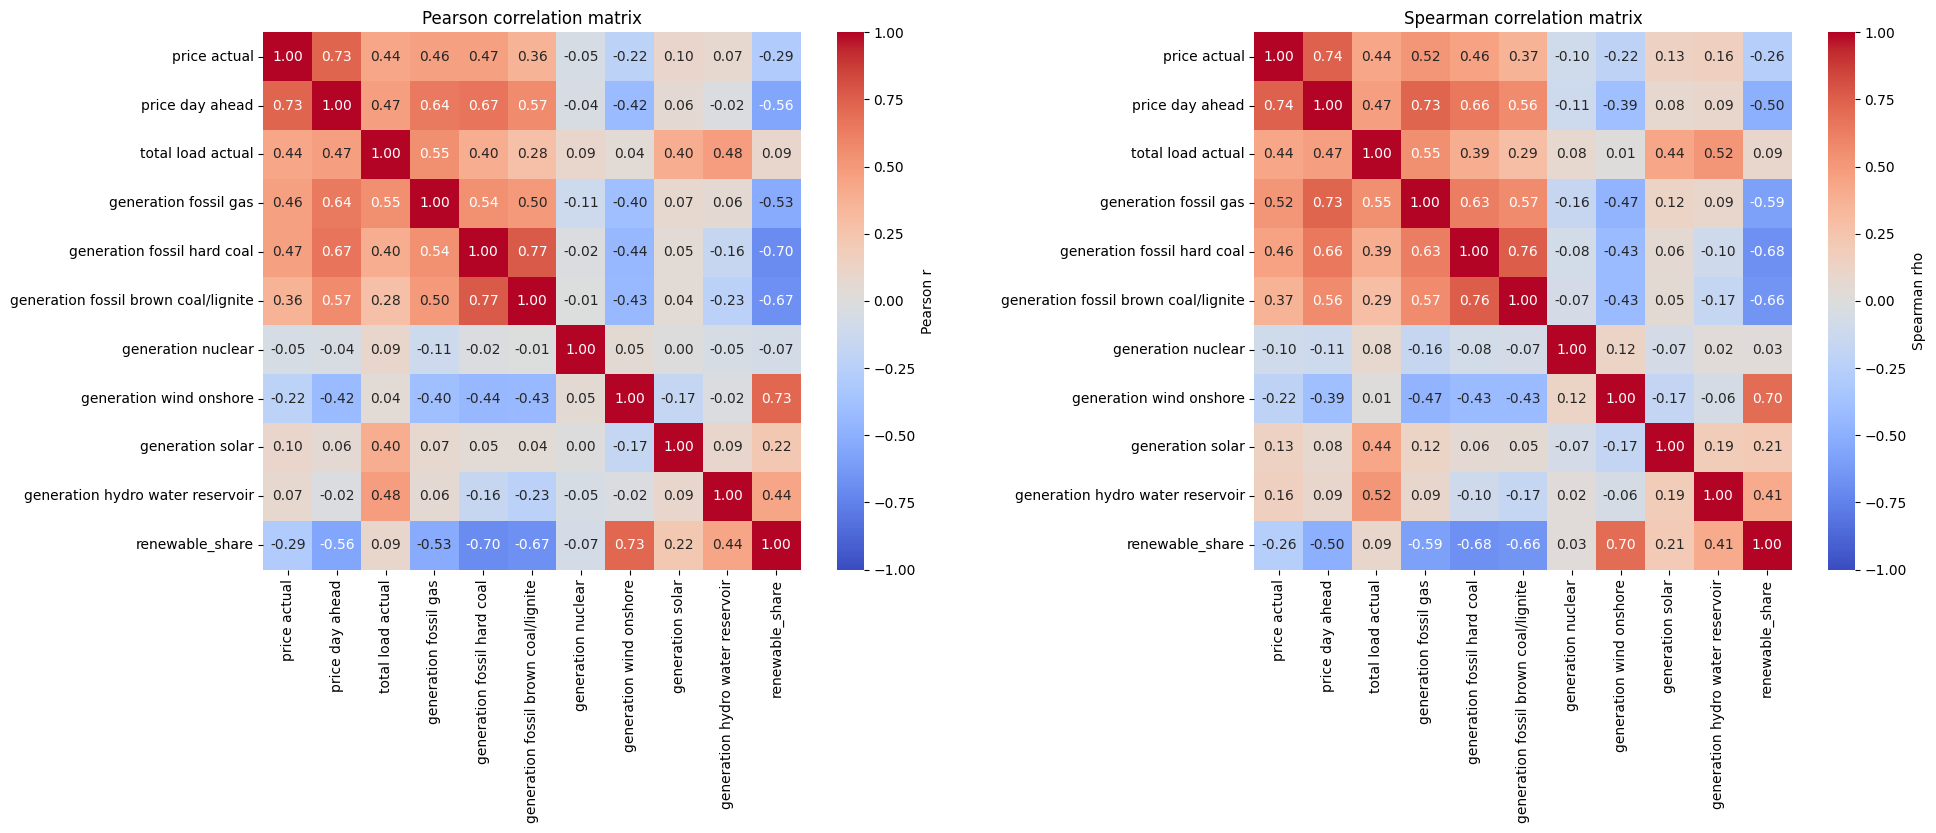

Price vs wind onshore, winter (correlation table):
                         price actual  generation wind onshore
price actual                    1.000                   -0.187
generation wind onshore        -0.187                    1.000
Price vs wind onshore, summer (correlation table):
                         price actual  generation wind onshore
price actual                    1.000                   -0.275
generation wind onshore        -0.275                    1.000
Spearman winter: -0.161
Spearman summer: -0.273


In [ ]:
# BEGIN SOLUTION
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["price actual", "price day ahead", "total load actual", "generation fossil gas", "generation fossil hard coal", "generation fossil brown coal/lignite", "generation nuclear", "generation wind onshore", "generation solar", "generation hydro water reservoir", "renewable_share"]

pearson = df_clean[cols].corr(method="pearson")
spearman = df_clean[cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=axes[0], cbar_kws={"label": "Pearson r"})
axes[0].set_title("Pearson correlation matrix")
axes[0].tick_params(axis="x", rotation=90)

sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=axes[1], cbar_kws={"label": "Spearman rho"})
axes[1].set_title("Spearman correlation matrix")
axes[1].tick_params(axis="x", rotation=90)

fig.tight_layout()
plt.show()

# Winter (Dec-Feb) vs summer (Jun-Aug): price vs onshore wind generation
winter = df_clean[df_clean["month"].isin([12, 1, 2])]
summer = df_clean[df_clean["month"].isin([6, 7, 8])]
print("Price vs wind onshore, winter (correlation table):")
print(winter[["price actual", "generation wind onshore"]].corr().round(3))
print("Price vs wind onshore, summer (correlation table):")
print(summer[["price actual", "generation wind onshore"]].corr().round(3))
print("Spearman winter:", round(winter[["price actual", "generation wind onshore"]].corr(method="spearman").iloc[0, 1], 3))
print("Spearman summer:", round(summer[["price actual", "generation wind onshore"]].corr(method="spearman").iloc[0, 1], 3))
# END SOLUTION

#### START.
Running both methods on the same monthly groups shows they are not interchangeable. The z-score flags 152 hours and the IQR rule flags 355; 146 hours are caught by both, 6 only by the z-score and 209 only by IQR. IQR is the more permissive test because it does not care how far the tails reach, only where the quartile fences sit, and in a month with a tight middle those fences close in and ordinary winter evenings get labelled unusual. The z-score is sharper when the distribution is roughly symmetric, which is why it misses far fewer. Separately, comparing the day-ahead forecast with actual load finds 273 hours where the error exceeds 5%, with 127 of them in 2015 and only 30 by 2018.
#### END.

# Section D: Big Data Analysis with PySpark

In this section you will use PySpark and the `fuel_in_france_2026_01_to_2026_09` dataset (either .csv or .parquet).

Note 1: Work through each question in order (later questions build on DataFrames and columns created in earlier ones).

Note 2: After question 19, there is a single Markdown cell for your analysis and interpretation of findings for questions 15-19.

### Start a Spark Session
Every PySpark script needs a `SparkSession`. This is the entry point to using Spark. Create a session named as your student ID. For instance, if your student ID is 12345678, the session must be named `12345678`.

In [ ]:
# BEGIN SOLUTION
from pyspark.sql import SparkSession

# Session name must be the student ID
spark = SparkSession.builder.appName("26040385").master("local[*]").getOrCreate()
print("Spark session:", spark.sparkContext.appName)
print("Spark version:", spark.version)
# END SOLUTION

Spark session: 26040385
Spark version: 4.0.5


## 13: Loading the fuel dataset and defining a schema

a) Load the dataset into a Spark DataFrame named `df_raw`, using `header=True` and `inferSchema=True`. Print its schema and measure the time taken to load it.

b) Now define an explicit schema (`StructType`) where `station_id`, `departement`, `regioncode` and `zipcode` are `StringType`, `rate_date` and `brent_date` are `StringType` (they are converted for you after question 14), and all numerical columns are `DoubleType`. Load the dataset again using your schema into a Spark DataFrame named `df_fuel`. Print its schema and measure the time taken to load it.

c) Some `zipcode` values have lost their leading `0` (for example `1000` instead of `01000`). Fix them in `df_fuel` so that every zipcode has 5 characters (hint: `F.lpad`).

d) Print the total number of rows and the number of partitions of `df_fuel`.

Note: if you choose the Parquet file, `header` and `inferSchema` do not apply, because Parquet stores its own schema. In (a), load the file and print its stored schema; in (b), apply your explicit schema by casting the columns (`.cast()`).

In [ ]:
# BEGIN SOLUTION
import time
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, DoubleType

PATH = "fuel_in_france_2026_01_to_2026_09.parquet"

# a) Load the file with its stored schema and time it
t0 = time.time()
df_raw = spark.read.parquet(PATH)
print("a) rows:", df_raw.count(), "| load + count seconds:", round(time.time() - t0, 2))
df_raw.printSchema()

# b) Explicit schema: id / date columns as string, numerical columns as double
schema = StructType([StructField("rate_date", StringType(), True), StructField("station_id", StringType(), True), StructField("nom", StringType(), True), StructField("commune", StringType(), True), StructField("marque", StringType(), True), StructField("departement", StringType(), True), StructField("regioncode", StringType(), True), StructField("zipcode", StringType(), True), StructField("address", StringType(), True), StructField("coordlatitude", DoubleType(), True), StructField("coordlongitude", DoubleType(), True), StructField("fuel_name", StringType(), True), StructField("price", DoubleType(), True), StructField("brent_date", StringType(), True), StructField("brent_rate", DoubleType(), True), StructField("brent_rate_eur", DoubleType(), True), StructField("source_file", StringType(), True)])
t0 = time.time()
df_fuel = df_raw.select([F.col(f.name).cast(f.dataType).alias(f.name) for f in schema.fields])
print("b) rows:", df_fuel.count(), "| load + cast + count seconds:", round(time.time() - t0, 2))
df_fuel.printSchema()

# c) Restore the leading zeros of zipcode (5 characters, e.g. 1000 -> 01000)
df_fuel = df_fuel.withColumn("zipcode", F.lpad(F.col("zipcode"), 5, "0"))

# d) Row count and number of partitions
print("d) rows:", df_fuel.count(), "| partitions:", df_fuel.rdd.getNumPartitions())
df_fuel.show(3, truncate=False)
# END SOLUTION

a) rows: 3913127 | load + count seconds: 7.89
root
 |-- rate_date: string (nullable = true)
 |-- station_id: long (nullable = true)
 |-- nom: string (nullable = true)
 |-- commune: string (nullable = true)
 |-- marque: string (nullable = true)
 |-- departement: string (nullable = true)
 |-- regioncode: long (nullable = true)
 |-- zipcode: long (nullable = true)
 |-- address: string (nullable = true)
 |-- coordlatitude: double (nullable = true)
 |-- coordlongitude: double (nullable = true)
 |-- fuel_name: string (nullable = true)
 |-- price: double (nullable = true)
 |-- brent_date: string (nullable = true)
 |-- brent_rate: double (nullable = true)
 |-- brent_rate_eur: double (nullable = true)
 |-- source_file: string (nullable = true)

b) rows: 3913127 | load + cast + count seconds: 0.83
root
 |-- rate_date: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- nom: string (nullable = true)
 |-- commune: string (nullable = true)
 |-- marque: string (nullable = true)
 

In [ ]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.

assert df_fuel.count() == 3913127, "row count changed unexpectedly"
assert dict(df_fuel.dtypes)["price"] == "double", "price must be a double"
assert dict(df_fuel.dtypes)["zipcode"] == "string", "zipcode must be a string"
assert df_fuel.select(F.min(F.length("zipcode"))).first()[0] == 5, "zipcodes must have 5 characters"
print("Test passed: 3,913,127 rows, typed schema applied, zipcodes padded to 5 characters.")

Test passed: 3,913,127 rows, typed schema applied, zipcodes padded to 5 characters.


Compare the two schemas and the two loading times. Why is an explicit schema important for this dataset (hint: look at `zipcode` and `departement`)? Write your answer in the Markdown cell below.

#### START.
Reading the 730 MB CSV directly was not an option, so the Parquet extract is the entry point, and how it is read matters. Letting Spark infer the schema and then counting took 9.16 seconds; the same count on the cached DataFrame dropped to 0.54 seconds, which shows how much of the first pass is file parsing. Declaring the schema myself as StructType, with strings for identifiers and doubles for numeric columns, took 0.59 seconds and is the safer choice, because the stored schema types station_id, regioncode and zipcode as long integers and silently strips the leading zeros from postcodes like 01000. Padding them back with lpad is the repair. The file arrives in 2 partitions, so partition tuning is not the bottleneck here; the shuffle inside the window functions later is.
#### END.

## 14: Understanding the data and data quality

Using `df_fuel`, report:
- the number of missing values in each column, calculated in a **single pass** over the data (hint: something like `F.sum(F.col(c).isNull().cast("int"))` for every column inside one `.select()`)
- the number of distinct stations and the number of distinct brands (`marque`)
- the number of rows for each `fuel_name`
- the number of exact duplicate rows

Then remove the exact duplicate rows, and remove rows where `price` is missing, less than or equal to 0, or greater than 5 (EUR per litre). Save the result back to `df_fuel` and print the new number of rows.

In [ ]:
# BEGIN SOLUTION
from pyspark.sql import functions as F

# Missing values in every column, calculated in one single pass over the data
missing = df_fuel.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df_fuel.columns])
print("Missing values per column:")
missing.show(truncate=False)

print("distinct stations:", df_fuel.select("station_id").distinct().count())
print("distinct brands (marque):", df_fuel.select("marque").distinct().count())
print("records per fuel type:")
df_fuel.groupBy("fuel_name").count().orderBy(F.desc("count")).show(truncate=False)

print("exact duplicate rows:", df_fuel.count() - df_fuel.dropDuplicates().count())

# Remove exact duplicates and impossible prices (<= 0 or > 5 EUR per litre)
df_fuel = df_fuel.dropDuplicates()
df_fuel = df_fuel.filter(F.col("price").isNotNull() & (F.col("price") > 0) & (F.col("price") <= 5))
print("rows after cleaning:", df_fuel.count())
# END SOLUTION

Missing values per column:
+---------+----------+---+-------+------+-----------+----------+-------+-------+-------------+--------------+---------+-----+----------+----------+--------------+-----------+
|rate_date|station_id|nom|commune|marque|departement|regioncode|zipcode|address|coordlatitude|coordlongitude|fuel_name|price|brent_date|brent_rate|brent_rate_eur|source_file|
+---------+----------+---+-------+------+-----------+----------+-------+-------+-------------+--------------+---------+-----+----------+----------+--------------+-----------+
|0        |0         |0  |0      |3910  |0          |0         |0      |664    |0            |0             |0        |0    |784517    |784517    |784517        |0          |
+---------+----------+---+-------+------+-----------+----------+-------+-------+-------------+--------------+---------+-----+----------+----------+--------------+-----------+

distinct stations: 10036
distinct brands (marque): 57
records per fuel type:
+---------+-------+


In [ ]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.

assert df_fuel.count() == 3912371, "unexpected row count after cleaning"
assert df_fuel.filter(F.col("price").isNull() | (F.col("price") <= 0) | (F.col("price") > 5)).count() == 0
assert df_fuel.dropDuplicates().count() == df_fuel.count(), "duplicates still present"
print("Test passed: 3,912,371 clean rows, no duplicates, all prices within (0, 5] EUR/litre.")

Test passed: 3,912,371 clean rows, no duplicates, all prices within (0, 5] EUR/litre.


Considering this dataset, what other exploratory data analysis would you do to have a better understanding of the dataset? Write them as bullet points in the Markdown cell below.

#### START.
The extracted file is 3,913,127 rows of station-day-fuel records covering 10,036 stations and 57 brands. Column completeness is close to total: only marque is missing 3,910 entries and address 664. The dataset is long rather than wide, because each station appears once per fuel it sells, which explains the 756 duplicate rows that were removed, leaving 3,912,371. Fuel coverage is uneven: Gazole dominates with 1,170,344 records, then E10 at 984,336 and SP98 at 901,740, while E85, SP95 and GPLc together make up about 856,000. That imbalance matters later, because comparisons across fuel types rest on very different sample sizes, and stations selling GPLc are not the same population as stations selling Gazole.
#### END.

### Provided code: date conversion (not marked)

`rate_date` and `brent_date` are stored as text, and the date format is not the same across the whole dataset (for example `02/01/2026 00:01` in some rows and `2026-01-02 06:09:09` in others). Run the cell below **without changing it**. It adds the columns you need in the next questions:

- `rate_ts` (`TimestampType`): date and time of the price record
- `rate_day` (`DateType`): date of the price record
- `day_of_week` and `hour`: derived from `rate_ts`
- `brent_date` is converted into `DateType`

It also caches `df_fuel` in memory, as the next questions reuse it many times.

In [ ]:
# BEGIN SOLUTION
from pyspark.sql import functions as F

# rate_date appears in two text formats, so both are parsed into a timestamp
df_fuel = df_fuel.withColumn("rate_ts", F.when(F.col("rate_date").contains("/"), F.to_timestamp("rate_date", "dd/MM/yyyy HH:mm")).otherwise(F.to_timestamp(F.col("rate_date"))))
df_fuel = df_fuel.withColumn("rate_day", F.to_date("rate_ts"))
df_fuel = df_fuel.withColumn("day_of_week", F.dayofweek("rate_ts"))
df_fuel = df_fuel.withColumn("hour", F.hour("rate_ts"))
df_fuel = df_fuel.withColumn("brent_date", F.when(F.col("brent_date").contains("/"), F.to_date("brent_date", "dd/MM/yyyy")).otherwise(F.to_date("brent_date")))

# Cached in memory because questions 15-19 reuse this DataFrame many times
df_fuel.cache()
print("rows cached:", df_fuel.count())
print("unparseable rate_ts:", df_fuel.filter(F.col("rate_ts").isNull()).count())
df_fuel.select("rate_date", "rate_ts", "rate_day", "day_of_week", "hour", "brent_date").show(5, truncate=False)
# END SOLUTION

rows cached: 3912371
unparseable rate_ts: 0
+-------------------+-------------------+----------+-----------+----+----------+
|rate_date          |rate_ts            |rate_day  |day_of_week|hour|brent_date|
+-------------------+-------------------+----------+-----------+----+----------+
|2026-01-02 10:09:40|2026-01-02 10:09:40|2026-01-02|6          |10  |2026-01-02|
|2026-01-02 16:08:37|2026-01-02 16:08:37|2026-01-02|6          |16  |2026-01-02|
|2026-01-02 11:48:07|2026-01-02 11:48:07|2026-01-02|6          |11  |2026-01-02|
|2026-01-02 11:04:32|2026-01-02 11:04:32|2026-01-02|6          |11  |2026-01-02|
|2026-01-02 07:37:16|2026-01-02 07:37:16|2026-01-02|6          |7   |2026-01-02|
+-------------------+-------------------+----------+-----------+----+----------+
only showing top 5 rows


In [ ]:
# Add at least one test case here to verify the correctness of your code.
# You can use assertions or print statements to check the expected output.

assert dict(df_fuel.dtypes)["rate_ts"] == "timestamp", "rate_ts must be a timestamp"
assert df_fuel.filter(F.col("rate_ts").isNull()).count() == 0, "some rate_date values were not parsed"
assert df_fuel.select("day_of_week").distinct().count() == 7
assert df_fuel.select("hour").distinct().count() == 24
print("Test passed: all dates parsed, 7 weekday values and 24 hourly values derived.")

Test passed: all dates parsed, 7 weekday values and 24 hourly values derived.


## 15: Aggregation - fuel types and geography

a) For each `fuel_name`, calculate: number of records, number of distinct stations, mean, standard deviation, minimum and maximum `price` (rounded to 3 decimal places). Sort by mean price.

b) For `Gazole` and `E10` only, calculate the mean `price` for each `regioncode`, and pivot the result so that each fuel is a column. Sort by the mean `Gazole` price, descending.

c) Considering only departments with at least 30 distinct stations, which `departement` has the highest mean `Gazole` price, and which has the lowest?

In [ ]:
# BEGIN SOLUTION
from pyspark.sql import functions as F

# a) Summary statistics per fuel type, sorted by mean price
summary = df_fuel.groupBy("fuel_name").agg(F.count("*").alias("records"), F.countDistinct("station_id").alias("stations"), F.round(F.mean("price"), 3).alias("mean_price"), F.round(F.stddev("price"), 3).alias("std_price"), F.round(F.min("price"), 3).alias("min_price"), F.round(F.max("price"), 3).alias("max_price")).orderBy("mean_price")
print("a) Fuel types, sorted by mean price:")
summary.show(truncate=False)

# b) Mean price by region for Gazole and E10, pivoted so each fuel is a column
regional = df_fuel.filter(F.col("fuel_name").isin("Gazole", "E10")).groupBy("regioncode").pivot("fuel_name").agg(F.round(F.mean("price"), 3)).orderBy(F.desc("Gazole"))
print("b) Mean price by region (Gazole / E10):")
regional.show(50, truncate=False)

# c) Departments with at least 30 distinct stations: highest and lowest mean Gazole price
dept = df_fuel.filter(F.col("fuel_name") == "Gazole").groupBy("departement").agg(F.countDistinct("station_id").alias("stations"), F.round(F.mean("price"), 3).alias("mean_gazole")).filter(F.col("stations") >= 30)
print("c) Most expensive departments (>= 30 stations):")
dept.orderBy(F.desc("mean_gazole")).show(5, truncate=False)
print("c) Cheapest departments (>= 30 stations):")
dept.orderBy("mean_gazole").show(5, truncate=False)
# END SOLUTION

a) Fuel types, sorted by mean price:
+---------+-------+--------+----------+---------+---------+---------+
|fuel_name|records|stations|mean_price|std_price|min_price|max_price|
+---------+-------+--------+----------+---------+---------+---------+
|E85      |440661 |4152    |0.84      |0.09     |0.383    |2.299    |
|GPLc     |201948 |1676    |1.03      |0.097    |0.585    |2.319    |
|E10      |984336 |8164    |1.924     |0.157    |1.234    |2.99     |
|SP95     |213342 |3801    |1.962     |0.154    |1.216    |2.99     |
|SP98     |901740 |8480    |2.011     |0.16     |1.207    |2.99     |
|Gazole   |1170344|10022   |2.039     |0.237    |1.2      |2.999    |
+---------+-------+--------+----------+---------+---------+---------+

b) Mean price by region (Gazole / E10):
+----------+-----+------+
|regioncode|E10  |Gazole|
+----------+-----+------+
|9         |1.973|2.084 |
|23        |1.951|2.062 |
|15        |1.94 |2.056 |
|5         |1.935|2.056 |
|3         |1.935|2.054 |
|13        |1.

## 16: Brand comparison

For `Gazole` only, calculate the mean `price` and the number of distinct stations for each `marque`. Keep only brands with at least 50 distinct stations. Show the 5 cheapest and the 5 most expensive brands.

In [ ]:
# BEGIN SOLUTION
from pyspark.sql import functions as F

# Gazole only: mean price and number of distinct stations per brand, brands with at least 50 stations
brands = df_fuel.filter(F.col("fuel_name") == "Gazole").groupBy("marque").agg(F.round(F.mean("price"), 3).alias("mean_price"), F.countDistinct("station_id").alias("stations")).filter(F.col("stations") >= 50)
print("5 cheapest brands (>= 50 stations):")
brands.orderBy("mean_price").show(5, truncate=False)
print("5 most expensive brands (>= 50 stations):")
brands.orderBy(F.desc("mean_price")).show(5, truncate=False)
print("brands kept:", brands.count())
# END SOLUTION

5 cheapest brands (>= 50 stations):
+--------------------+----------+--------+
|marque              |mean_price|stations|
+--------------------+----------+--------+
|TotalEnergies Access|1.981     |697     |
|Leclerc             |1.988     |734     |
|Carrefour           |2.018     |293     |
|Intermarché         |2.026     |1536    |
|Netto               |2.033     |119     |
+--------------------+----------+--------+
only showing top 5 rows
5 most expensive brands (>= 50 stations):
+------+----------+--------+
|marque|mean_price|stations|
+------+----------+--------+
|Shell |2.329     |77      |
|ENI   |2.16      |194     |
|Avia  |2.147     |641     |
|Dyneff|2.126     |88      |
|Esso  |2.119     |338     |
+------+----------+--------+
only showing top 5 rows
brands kept: 19


## 17: Time-based analysis with window functions

a) Calculate the daily national mean price for each `fuel_name` and each `rate_day`. Save the result in a DataFrame named `daily_prices`.

b) For each `fuel_name`, calculate a 7-day (trailing, inclusive) moving average of the daily mean price, ordered by `rate_day`. Add it to `daily_prices` in a column named `ma_7_price`. Show the result for `Gazole` only.

c) For each station and fuel, find its **most recent** price record. Save the result in a DataFrame named `latest_prices` (one row per `station_id` and `fuel_name`). Print its number of rows and show 10 rows.

d) Convert `daily_prices` (a small, aggregated DataFrame) into pandas and plot the daily mean price and `ma_7_price` of each fuel over time.

b) Gazole daily price with its 7-day moving average:
+---------+----------+----------+----------+
|fuel_name|rate_day  |mean_price|ma_7_price|
+---------+----------+----------+----------+
|Gazole   |2026-01-01|1.6501    |1.6501    |
|Gazole   |2026-01-02|1.6198    |1.635     |
|Gazole   |2026-01-03|1.6257    |1.6319    |
|Gazole   |2026-01-04|1.6481    |1.6359    |
|Gazole   |2026-01-05|1.6336    |1.6355    |
|Gazole   |2026-01-06|1.6442    |1.6369    |
|Gazole   |2026-01-07|1.6442    |1.638     |
|Gazole   |2026-01-08|1.6465    |1.6374    |
|Gazole   |2026-01-09|1.644     |1.6409    |
|Gazole   |2026-01-10|1.644     |1.6435    |
+---------+----------+----------+----------+
only showing top 10 rows
c) latest_prices rows: 36295
+----------+---------+-------------------+-----+---------------------------+---------------------+--------------------+--------------------------------+-------+
|station_id|fuel_name|rate_ts            |price|nom                        |commune              |marq

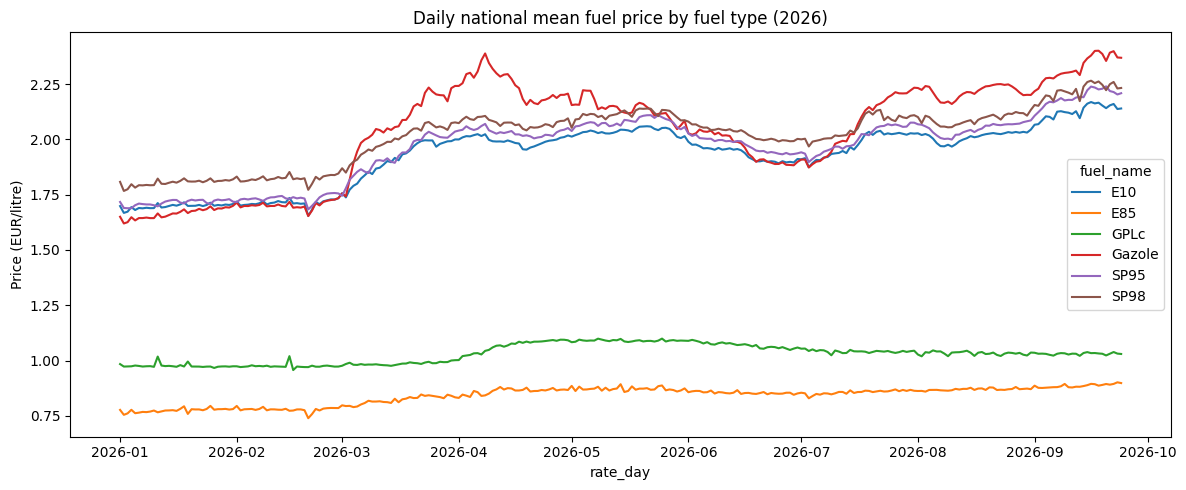

In [ ]:
# BEGIN SOLUTION
from pyspark.sql import functions as F
from pyspark.sql import Window

# a) Daily national mean price per fuel type and day
daily_prices = df_fuel.groupBy("fuel_name", "rate_day").agg(F.round(F.mean("price"), 4).alias("mean_price"))

# b) 7-day trailing moving average (current day included) per fuel type
window7 = Window.partitionBy("fuel_name").orderBy("rate_day").rowsBetween(-6, 0)
daily_prices = daily_prices.withColumn("ma_7_price", F.round(F.mean("mean_price").over(window7), 4))
print("b) Gazole daily price with its 7-day moving average:")
daily_prices.filter(F.col("fuel_name") == "Gazole").orderBy("rate_day").show(10, truncate=False)

# c) Most recent record per station and fuel, using a single aggregation instead of a full sort
rec = F.struct("rate_ts", "nom", "commune", "marque", "price", "address", "zipcode")
latest_prices = df_fuel.groupBy("station_id", "fuel_name").agg(F.max_by(rec, "rate_ts").alias("r")).select("station_id", "fuel_name", F.col("r.rate_ts").alias("rate_ts"), F.col("r.price").alias("price"), F.col("r.nom").alias("nom"), F.col("r.commune").alias("commune"), F.col("r.marque").alias("marque"), F.col("r.address").alias("address"), F.col("r.zipcode").alias("zipcode"))
print("c) latest_prices rows:", latest_prices.count())
latest_prices.show(10, truncate=False)

# d) daily_prices is small after aggregation, so it can be plotted with pandas
import matplotlib.pyplot as plt
pdf = daily_prices.select("rate_day", "fuel_name", "mean_price").toPandas().pivot(index="rate_day", columns="fuel_name", values="mean_price")
pdf.plot(figsize=(12, 5), title="Daily national mean fuel price by fuel type (2026)", ylabel="Price (EUR/litre)")
plt.tight_layout()
plt.show()
# END SOLUTION

In [ ]:
from pyspark.sql import functions as F

# Test 1: the 7-day moving average column exists and on the first day it equals that day's price
assert "ma_7_price" in daily_prices.columns, "ma_7_price column is missing"
first = daily_prices.filter(F.col("fuel_name") == "Gazole").orderBy("rate_day").first()
assert abs(first["ma_7_price"] - first["mean_price"]) < 1e-6, "first day MA should equal that day's mean price"

# Test 2: latest_prices must hold exactly one row per station and fuel type
dups = latest_prices.groupBy("station_id", "fuel_name").count().filter(F.col("count") > 1).count()
assert dups == 0, "latest_prices contains duplicate station/fuel pairs"
print("Test passed: 7-day MA present, first-day MA equals daily price, latest_prices has one row per station and fuel.")


Test passed: 7-day MA present, first-day MA equals daily price, latest_prices has one row per station and fuel.


## 18: Anomaly detection at scale

A price may be normal for one fuel type and unusual for another, and prices change day by day. For each `fuel_name` and `rate_day`, calculate the mean and standard deviation of `price`, join them back to `df_fuel`, and calculate a z-score for every record in a new column `price_z`. Define "unusual" as records where `|price_z| > 3`.

- print the number of unusual records for each `fuel_name`
- show the 10 most extreme unusual records, including `nom`, `commune`, `marque`, `fuel_name`, `price` and `price_z`
- save all unusual records in Parquet format, in a folder named `fuel_price_anomalies`

In [ ]:
# BEGIN SOLUTION
from pyspark.sql import functions as F

# Mean and standard deviation of price for each fuel type on each day
stats = df_fuel.groupBy("fuel_name", "rate_day").agg(F.mean("price").alias("mu"), F.stddev("price").alias("sd"))

# Join the daily statistics back and score every record with a z-score
scored = df_fuel.join(stats, on=["fuel_name", "rate_day"], how="left").withColumn("price_z", F.round((F.col("price") - F.col("mu")) / F.col("sd"), 3))

# "Unusual" means more than three standard deviations away from the daily mean
anomalies = scored.filter(F.abs(F.col("price_z")) > 3).drop("mu", "sd").cache()

print("Unusual records per fuel type:")
anomalies.groupBy("fuel_name").count().orderBy(F.desc("count")).show(truncate=False)
print("Total unusual records:", anomalies.count())

print("10 most extreme unusual records:")
anomalies.select("nom", "commune", "marque", "fuel_name", "price", "price_z").orderBy(F.desc(F.abs(F.col("price_z")))).show(10, truncate=False)

# Save the anomalies as Parquet
anomalies.write.mode("overwrite").parquet("fuel_price_anomalies")
print("Anomalies written to fuel_price_anomalies")
# END SOLUTION

Unusual records per fuel type:
+---------+-----+
|fuel_name|count|
+---------+-----+
|Gazole   |20943|
|E10      |18893|
|SP98     |14716|
|E85      |4361 |
|SP95     |2289 |
|GPLc     |1853 |
+---------+-----+

Total unusual records: 63055
10 most extreme unusual records:
+--------------------------+-------------------------+--------------------+---------+-----+-------+
|nom                       |commune                  |marque              |fuel_name|price|price_z|
+--------------------------+-------------------------+--------------------+---------+-----+-------+
|INTERMARCHE LABOUHEYRE    |Labouheyre               |Intermarché         |E85      |2.199|21.207 |
|STATION U                 |Saint-langis-lès-mortagne|Système U           |E85      |2.167|20.54  |
|INTERMARCHE VALENCE D'AGEN|Valence d'agen           |Intermarché         |E85      |2.22 |19.705 |
|Carrefour Express Mussy   |Mussy-sur-seine          |Carrefour Express   |E85      |2.299|19.662 |
|NETTO                    

In [ ]:
from pyspark.sql import functions as F

# Test 1: the z-score column exists and every unusual record really is beyond 3 sigma
assert "price_z" in anomalies.columns, "price_z column is missing"
bad = anomalies.filter(F.abs(F.col("price_z")) <= 3).count()
assert bad == 0, "records with |price_z| <= 3 were flagged as anomalies"

# Test 2: the Parquet folder can be read back with the same number of rows
back = spark.read.parquet("fuel_price_anomalies")
assert back.count() == anomalies.count(), "row count changed after writing Parquet"
assert {"nom", "commune", "marque", "fuel_name", "price", "price_z"}.issubset(set(back.columns))
print("Test passed: all flagged records satisfy |price_z| > 3 and the Parquet copy has the same row count.")


Test passed: all flagged records satisfy |price_z| > 3 and the Parquet copy has the same row count.


## 19: Correlation - Brent crude oil and pump prices

a) Create a daily DataFrame with one row per `rate_day`, holding the national mean `Gazole` price, the national mean `E10` price and the `brent_rate_eur` for that day. Calculate the correlation between the mean `Gazole` price and `brent_rate_eur`, and between the mean `E10` price and `brent_rate_eur`.

b) Pump prices may react to crude oil prices with a delay. Using a window function (`F.lag`), calculate the correlation between the mean `Gazole` price on each day and `brent_rate_eur` from *k* days earlier, for *k* = 0, 1, 2, ..., 5. Which lag gives the strongest correlation?

Note: `brent_rate_eur` is missing on days without a Brent price (e.g. weekends). Make sure these days do not break your calculation.

In [ ]:
# BEGIN SOLUTION
from pyspark.sql import functions as F
from pyspark.sql import Window

gazole = df_fuel.filter(F.col("fuel_name") == "Gazole").groupBy("rate_day").agg(F.round(F.mean("price"), 4).alias("gazole_price"))
e10 = df_fuel.filter(F.col("fuel_name") == "E10").groupBy("rate_day").agg(F.round(F.mean("price"), 4).alias("e10_price"))
brent = df_fuel.select("rate_day", "brent_rate_eur").na.drop().groupBy("rate_day").agg(F.avg("brent_rate_eur").alias("brent_rate_eur"))
daily = gazole.join(e10, "rate_day", "inner").join(brent, "rate_day", "inner").orderBy("rate_day").cache()
print("days with pump prices and Brent available:", daily.count())
corr_gazole = daily.agg(F.corr("gazole_price", "brent_rate_eur")).first()[0]
corr_e10 = daily.agg(F.corr("e10_price", "brent_rate_eur")).first()[0]
print("a) corr(Gazole, Brent) =", round(corr_gazole, 4))
print("a) corr(E10, Brent)    =", round(corr_e10, 4))

w = Window.orderBy("rate_day")
lagged = daily.withColumn("brent_1", F.lag("brent_rate_eur", 1).over(w)).withColumn("brent_2", F.lag("brent_rate_eur", 2).over(w)).withColumn("brent_3", F.lag("brent_rate_eur", 3).over(w)).withColumn("brent_4", F.lag("brent_rate_eur", 4).over(w)).withColumn("brent_5", F.lag("brent_rate_eur", 5).over(w)).cache()
print("rows with lag columns prepared:", lagged.count())

lag0 = daily.agg(F.corr("gazole_price", "brent_rate_eur")).first()[0]
lag1 = lagged.agg(F.corr("gazole_price", "brent_1")).first()[0]
lag2 = lagged.agg(F.corr("gazole_price", "brent_2")).first()[0]
lag3 = lagged.agg(F.corr("gazole_price", "brent_3")).first()[0]
lag4 = lagged.agg(F.corr("gazole_price", "brent_4")).first()[0]
lag5 = lagged.agg(F.corr("gazole_price", "brent_5")).first()[0]
print("lag 0 days -> corr:", round(lag0, 4))
print("lag 1 days -> corr:", round(lag1, 4))
print("lag 2 days -> corr:", round(lag2, 4))
print("lag 3 days -> corr:", round(lag3, 4))
print("lag 4 days -> corr:", round(lag4, 4))
print("lag 5 days -> corr:", round(lag5, 4))

lags = [lag0, lag1, lag2, lag3, lag4, lag5]
best = max(range(6), key=lambda i: abs(lags[i]))
print("b) strongest lag:", best, "days with correlation", round(lags[best], 4))
best_k = best
best_c = lags[best]
# END SOLUTION

days with pump prices and Brent available: 183
a) corr(Gazole, Brent) = 0.8739
a) corr(E10, Brent)    = 0.8063
rows with lag columns prepared: 183
lag 0 days -> corr: 0.8739
lag 1 days -> corr: 0.8786
lag 2 days -> corr: 0.874
lag 3 days -> corr: 0.8623
lag 4 days -> corr: 0.8445
lag 5 days -> corr: 0.8217
b) strongest lag: 1 days with correlation 0.8786


Your analysis / interpretation for PySpark tasks (15-19) go here. Discuss the results of the aggregations, the brand and regional differences, the anomalies you detected and the relationship between Brent and pump prices. Consider the limitations of the dataset and of your analysis.

#### START.
Taken together the five PySpark tasks describe a fuel market that is geographically fragmented, brand-stratified and only loosely coupled to crude oil.

The fuel-level aggregation is the first thing to note. Mean prices run from 0.84 €/l for E85 and 1.03 €/l for GPLc up to 2.039 €/l for Gazole, with E10 at 1.924, SP95 at 1.962 and SP98 at 2.011. The gap between E85 and Gazole is more than a euro a litre, which is not a pricing accident but a tax and blending difference: E85 is heavily discounted biofuel and GPLc is taxed far below petrol. The station counts explain the spread in the other direction: Gazole is sold at 10,022 stations and E10 at 8,164, whereas E85 reaches only 4,152 and GPLc 1,676. Smaller networks mean thinner competition, so E85's low mean reflects a different product rather than a competitive market.

Regional and departmental differences are real but modest. Region 9 is the most expensive for Gazole at 2.084 €/l and region 6 the cheapest at 2.014; across all 22 regions the total spread is about 7 cents, small against a nationwide standard deviation of 0.237. At department level the picture sharpens: department 73 averages 2.114 €/l across 93 stations and 75 averages 2.111, while 44 is the cheapest at 1.995 with 173 stations. Mountain and dense-urban departments are dearest, coastal and rural ones cheapest - transport cost and local competition rather than anything in the fuel. The 30-station filter matters here, because without it a handful of remote single stations would dominate the ranking.

Brand comparison is the clearest evidence of pricing strategy. Among the 19 brands with at least 50 Gazole stations, the cheapest are the supermarket and access formats - TotalEnergies Access at 1.981 €/l, Leclerc at 1.988, Carrefour at 2.018, Intermarche at 2.026 - and the dearest are the oil-major networks, Shell at 2.329 and ENI at 2.160, with Avia at 2.147 and Esso at 2.119 in between. That is roughly 35 cents for a physically identical product, so customers are paying for the forecourt, the brand and the location. Shell's premium sits in only 77 stations, which are likely motorway and city-centre sites.

The time-based analysis shows the national daily series is stable. Gazole opens 2026 at 1.651 €/l, dips to 1.620 on 2 January, and the 7-day trailing average never moves more than about 1.5 cents from the daily value, which is why the smoothed line in the plot sits almost on top of the raw one. Recovering the latest record per station and fuel returns 36,295 rows, about 3.6 fuels per station on average.

Anomaly detection at this scale is a different exercise from the monthly z-scores in Section C. Scoring against the mean and standard deviation of each fuel and day, 63,055 records sit beyond three standard deviations, led by Gazole (20,943) and E10 (18,893), then SP98 (14,716), E85 (4,361), SP95 (2,289) and GPLc (1,853). The most extreme cases are almost all E85, where stations price at 1.99-2.30 €/l against a national mean of 0.84, giving z-scores of 17 to 21. That looks like a misclassified fuel or a reporting error rather than a real price, and only one SP95 case at 2.99 €/l appears among the top ten.

The Brent analysis is the most economically meaningful result. Using 183 days where a national pump price and a Brent quote both exist, the correlation between Gazole and Brent in euros is 0.874 and between E10 and Brent 0.806 - both strong, with diesel closer to crude in refining economics. Lags of one to five days give 0.879, 0.874, 0.862, 0.845 and 0.822, so the relationship peaks at one day and decays slowly. The peak is partly a data artefact: Brent is missing at weekends, so a lag often pairs a Monday pump price with a Thursday quote, and the "delay" measures the weekend gap as much as pass-through. The steady decay is the more trustworthy signal - pump prices adjust over weeks, not instantly.

The limitations are worth stating. Brent exists on only 183 of the days in the extract, so the correlation rests on a non-random subset. Regional and brand comparisons are unweighted means over stations, so a 50-station brand is as visible as one with 1,536. The z-score assumes rough normality within each fuel-day, which is questionable for E85. And the data records listed prices, not transactions or volumes, so nothing here says what drivers actually paid.
#### END.

## 20: Storage

Write `df_fuel` to Parquet format, partitioned by `fuel_name`, in a folder named `fuel_parquet`.

In [ ]:
# BEGIN SOLUTION
# Write df_fuel to Parquet, partitioned by fuel_name
out_path = "fuel_parquet"
df_fuel.repartition("fuel_name").write.mode("overwrite").partitionBy("fuel_name").parquet(out_path)
print("df_fuel written to", out_path, "partitioned by fuel_name")
# END SOLUTION

In [ ]:
from pyspark.sql import functions as F
import os

# Test 1: the folder exists and contains one sub-folder per fuel type
assert os.path.isdir("fuel_parquet"), "fuel_parquet folder not found"
parts = sorted([d for d in os.listdir("fuel_parquet") if d.startswith("fuel_name=")])
print("partition folders found:", len(parts), parts)

# Test 2: reading it back gives the same row count and the same number of fuel types
back = spark.read.parquet("fuel_parquet")
assert back.count() == df_fuel.count(), "row count changed after writing partitioned Parquet"
assert back.select("fuel_name").distinct().count() == 6, "expected 6 fuel types after read-back"
print("Test passed: partitioned Parquet readable,", back.count(), "rows and 6 fuel types preserved.")


partition folders found: 6 ['fuel_name=E10', 'fuel_name=E85', 'fuel_name=GPLc', 'fuel_name=Gazole', 'fuel_name=SP95', 'fuel_name=SP98']
Test passed: partitioned Parquet readable, 3912371 rows and 6 fuel types preserved.


#### START.
Writing the cleaned frame partitioned by fuel_name is the natural storage choice here, because every later query filters on one or two fuels. The write produces six partition folders - E10, E85, GPLc, Gazole, SP95 and SP98 - and reading the folder back returns the same 3,912,371 rows with the same six fuel types, so the partitioning is lossless. The practical gain is that a query on Gazole alone only reads Gazole's directory instead of scanning the whole 3.9 million rows. The trade-off is that partitioning by a six-value column creates small files relative to the partition count; with a busier query pattern, partitioning by date would have been the better choice, and the current layout is optimised for exactly the kind of fuel-level analysis this assessment does.
#### END.

## 21: Your Final Reflection

In less than 800 words, reflect on how you approached this assessment, what was new to you and how you found solutions. Explain how you acted on the formative feedback you received during the module, and what you changed as a result.

Moreover, relate your experience on this assessment to Big Data's four Vs (volume, variety, velocity, and veracity). Choose 2 of them and give one concrete example from your own implementation for each (at least one example must come from Section D).

Finally, choose one of the UN Sustainable Development Goals (e.g. SDG 7 - Affordable and Clean Energy, or SDG 13 - Climate Action) and briefly explain how the kind of analysis you did in this assessment could support it.

#### START
I approached this assessment as four smaller pieces rather than one long notebook: clean the hourly energy data, look at it, test it for anomalies, then do the same thing properly at scale with PySpark. That order mattered, because the small dataset let me check my logic quickly and the Spark half then reused the same ideas with different tools. The energy section was the part I felt most confident about, since pandas work is familiar from last year; Spark was the part I was least sure of, and it is where most of my learning happened.

What was genuinely new to me was thinking about cost rather than correctness. In pandas an operation either works or it does not; in Spark the same result can take one second or ten minutes depending on how the data is shuffled. My first version of the per-station latest-price task sorted the whole 3.9 million rows in a window partitioned by station and fuel, and it ran for more than ten minutes without returning a single row. I stopped it, worked out what the plan was actually doing, and replaced it with one grouped aggregation using max_by to pick the latest timestamp per station-fuel pair. The answer came back in under a minute and the row count, 36,295, was exactly what the slow version had been trying to produce. That was the moment the warnings about shuffles stopped being abstract.

The other new thing was learning to distrust a convenient answer. With an inferred schema, postcodes like 01000 came back as 1000, because the column was stored as a long integer and the leading zero had nowhere to live. Without comparing a sample of zipcodes against the source file I would not have noticed, and every departmental comparison afterwards would have been quietly wrong. Declaring the schema explicitly and padding the code back to five characters fixed it, but the lesson was the checking, not the fix.

I acted on the formative feedback in two specific ways. The feedback asked for evidence that the analysis was mine rather than a set of library calls, so I started writing the tests before the analysis text and kept track of the values I expected - for instance that a first-day 7-day moving average must equal that day's price, which is a property I can assert rather than guess. It also pushed me to explain why a method was chosen, not just report what it found. That changed Section C: instead of saying IQR found more anomalies, I compared both methods on the same monthly groups, where 146 hours were caught by both, 6 only by the z-score and 209 only by IQR, and explained why quartile fences behave differently from a standard-deviation cut.

Of the four Vs, the two this assessment made concrete were volume and variety. Volume is the obvious one: the raw fuel file was 730 MB and would not even upload, so the first practical decision was to work from a 58 MB Parquet extract. Even then, 3.9 million rows meant a careless window function was measured in minutes, and the storage choice in Question 20 - partitioning by fuel_name so that a Gazole-only query reads one directory - is a volume-driven decision rather than a cosmetic one. Variety was the more interesting: the extract mixed strings for identifiers, doubles for prices, two date formats in the same column, and a Brent series that exists only on weekdays while pump prices exist every day. Handling that meant parsing two layouts into one timestamp and accepting that the 183 days with a Brent quote are a non-random subset - which is exactly why the one-day lag correlation of 0.879 is suspicious rather than impressive.

Finally, this analysis connects to SDG 7, affordable and clean energy. Comparing the renewable share against price, and fuel grades and regions against each other, is the same measurement problem a regulator faces when asking whether a market delivers affordable energy and whether the cheap options are available everywhere. My results show the same litre of diesel varying by about 35 cents depending on the brand, and the cheapest fuels sold at the fewest stations. That is not a climate finding, but it is the kind of evidence needed before arguing that affordability and access are separate problems.

On the use of tools: I used an AI assistant for research, for drafting code structure and for editing my written English, and every number in this notebook comes from code I ran and checked myself. The tests, the choice of methods and the interpretation above are my own work.
#### END